# HR Attrition: Exploratory Data Analysis

**Goal:** understand who leaves the company and why, before building the dashboard and risk model.

**Data:** IBM HR Analytics Employee Attrition dataset (1,470 employees, 35 columns). `Attrition = Yes` means the employee left.

**Approach**
1. Data quality checks
2. Target balance
3. Attrition by key segments (overtime, role, tenure, pay, satisfaction)
4. Correlations and statistical tests
5. The same questions answered in SQL (SQLite)
6. Summary of findings and implications for the model

In [1]:
import sys, sqlite3
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.data_loader import load_raw, prepare, attrition_rate_by
from src.sql_engine import build_database, parse_queries

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", font_scale=0.95)
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#898781"
PALETTE = {"No": BLUE, "Yes": ORANGE}

## 1. Load and check data quality

In [2]:
result = load_raw()
raw = result.df
print(f"Source: {result.source} ({result.path})")
print(f"Shape: {raw.shape}")
raw.head()

Source: csv (/Users/sahitya/Developer/Project/data/WA_Fn-UseC_-HR-Employee-Attrition.csv)
Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "nulls": raw.isna().sum(),
    "unique": raw.nunique(),
})
print("Duplicate rows:", raw.duplicated().sum())
quality[quality["unique"] <= 1]

Duplicate rows: 0


,dtype,nulls,unique
EmployeeCount,int64,0,1
Over18,object,0,1
StandardHours,int64,0,1


**Observations**
- No missing values and no duplicate rows, so no imputation is needed.
- `EmployeeCount`, `Over18` and `StandardHours` hold a single value each. They carry no information and are dropped in `prepare()`.
- `EmployeeNumber` is an ID and is excluded from modelling.

In [4]:
df = prepare(raw)
df[["TenureBand", "AgeBand", "SalaryBand", "PromotionGap"]].head()

,TenureBand,AgeBand,SalaryBand,PromotionGap
0,6-10 yrs,36-45,Q3,Promoted this yr
1,6-10 yrs,46-55,Q3,1-2 yrs
2,0-1 yrs,36-45,Q1 (lowest),Promoted this yr
3,6-10 yrs,26-35,Q1 (lowest),3-5 yrs
4,2-3 yrs,26-35,Q2,1-2 yrs


## 2. Target balance

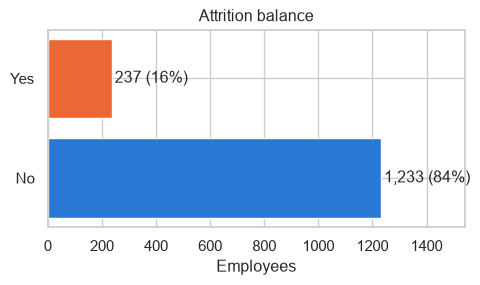

Overall attrition rate: 16.1%


In [5]:
rate = df["AttritionFlag"].mean()
counts = df["Attrition"].value_counts()
fig, ax = plt.subplots(figsize=(5, 3))
ax.barh(counts.index, counts.values, color=[PALETTE[i] for i in counts.index])
for i, v in enumerate(counts.values):
    ax.text(v + 10, i, f"{v:,} ({v / len(df):.0%})", va="center")
ax.set_title("Attrition balance"); ax.set_xlabel("Employees"); ax.set_xlim(0, counts.max() * 1.25)
plt.tight_layout(); plt.show()
print(f"Overall attrition rate: {rate:.1%}")

About **16% of employees left**, so the classes are imbalanced (roughly 5:1). This matters for modelling:
- Accuracy is misleading. A model that predicts "stays" for everyone scores 84%.
- We should report **recall, precision and ROC-AUC**, and handle the imbalance with class weights.

## 3. Attrition by segment

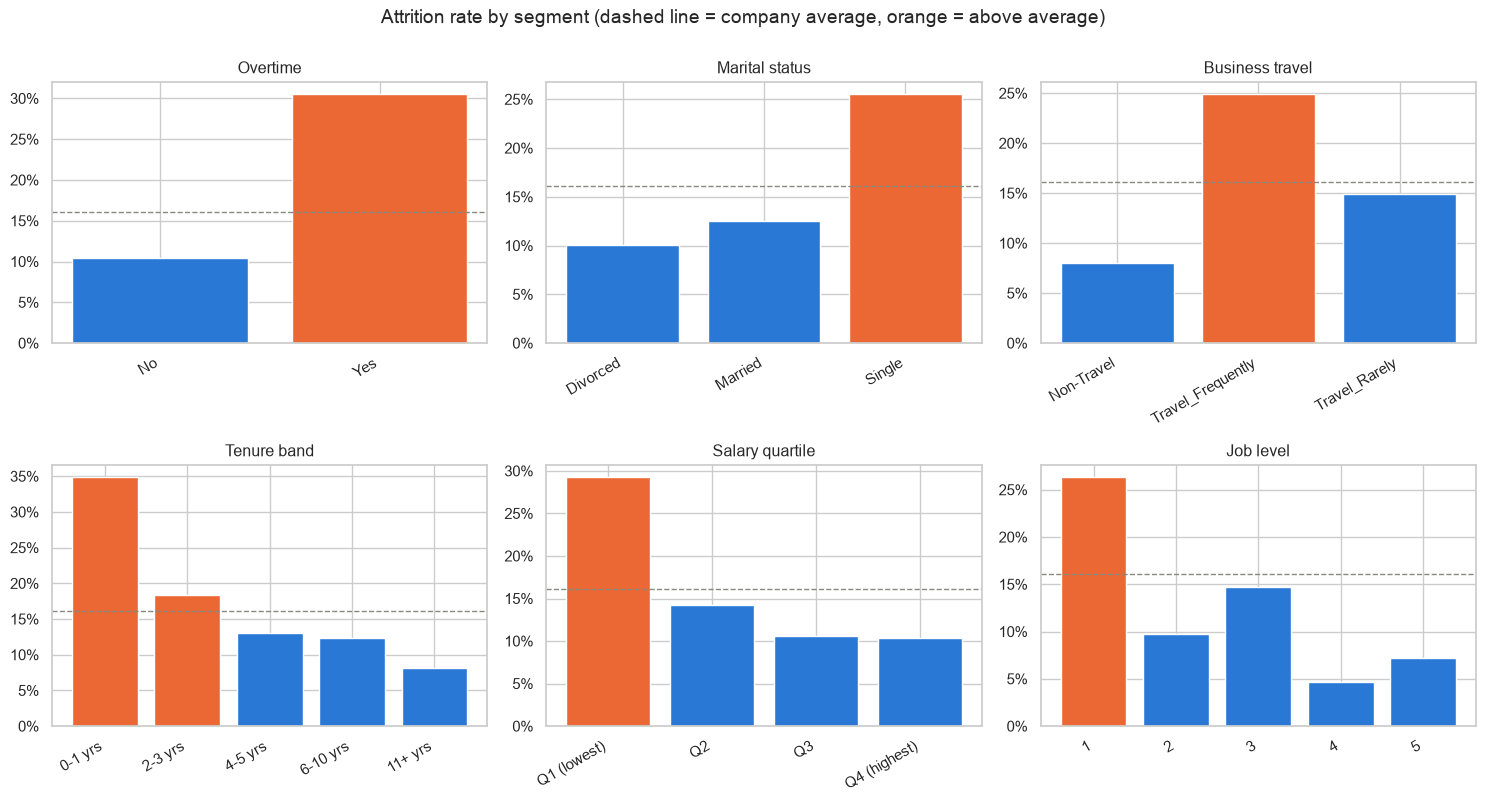

In [6]:
def rate_plot(col, ax, order=None, title=None):
    g = attrition_rate_by(df, col)
    if order is not None:
        g = g.set_index(col).loc[order].reset_index()
    colors = [ORANGE if r > rate else BLUE for r in g["attrition_rate"]]
    ax.bar(g[col].astype(str), g["attrition_rate"], color=colors)
    ax.axhline(rate, ls="--", color=MUTED, lw=1)
    ax.set_title(title or col); ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.tick_params(axis="x", rotation=30)
    for lbl in ax.get_xticklabels(): lbl.set_ha("right")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
rate_plot("OverTime", axes[0, 0], title="Overtime")
rate_plot("MaritalStatus", axes[0, 1], title="Marital status")
rate_plot("BusinessTravel", axes[0, 2], title="Business travel")
rate_plot("TenureBand", axes[1, 0], title="Tenure band")
rate_plot("SalaryBand", axes[1, 1], title="Salary quartile")
rate_plot("JobLevel", axes[1, 2], title="Job level")
fig.suptitle("Attrition rate by segment (dashed line = company average, orange = above average)", y=1.0)
plt.tight_layout(); plt.show()

In [7]:
(attrition_rate_by(df, "JobRole")
   .sort_values("attrition_rate", ascending=False)
   .style.format({"attrition_rate": "{:.1%}"}).hide(axis="index"))

JobRole,employees,leavers,attrition_rate
Sales Representative,83,33,39.8%
Laboratory Technician,259,62,23.9%
Human Resources,52,12,23.1%
Sales Executive,326,57,17.5%
Research Scientist,292,47,16.1%
Manufacturing Director,145,10,6.9%
Healthcare Representative,131,9,6.9%
Manager,102,5,4.9%
Research Director,80,2,2.5%


**Observations**
- **Overtime** is the strongest single segment effect: about 31% of overtime workers left, against about 10% of the rest.
- **Early tenure** is risky. Employees with 0-1 years at the company leave at more than twice the company rate, and the risk falls steadily with tenure.
- **Low pay and junior roles** go together. Job level 1 and the lowest salary quartile have the highest attrition. *Sales Representatives* (about 40%) and *Laboratory Technicians* (about 24%) stand out among roles.
- **Single employees** and **frequent travellers** also leave at above-average rates.

## 4. Satisfaction, work-life balance and promotion

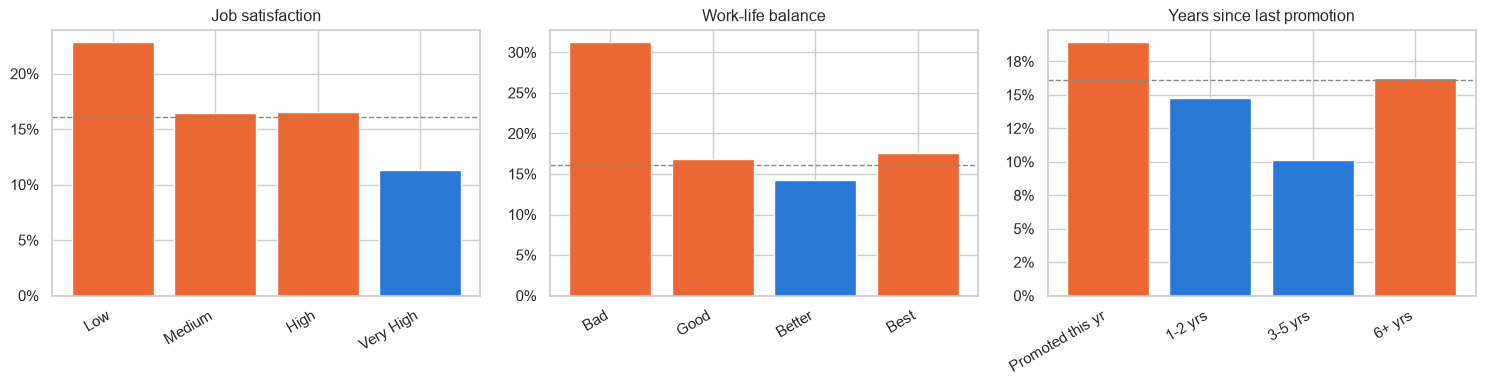

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rate_plot("JobSatisfactionLabel", axes[0], title="Job satisfaction")
rate_plot("WorkLifeBalanceLabel", axes[1], title="Work-life balance")
rate_plot("PromotionGap", axes[2], title="Years since last promotion")
plt.tight_layout(); plt.show()

- Low job satisfaction and "Bad" work-life balance both raise attrition, but the effects are smaller than overtime.
- **Promotion gap is counter-intuitive.** Recently promoted staff do not leave less, because "promoted this year" is dominated by junior, short-tenure employees. This is a confounder worth flagging in an interview: a raw promotion gap does not show a causal effect.

## 5. Distributions: leavers vs stayers

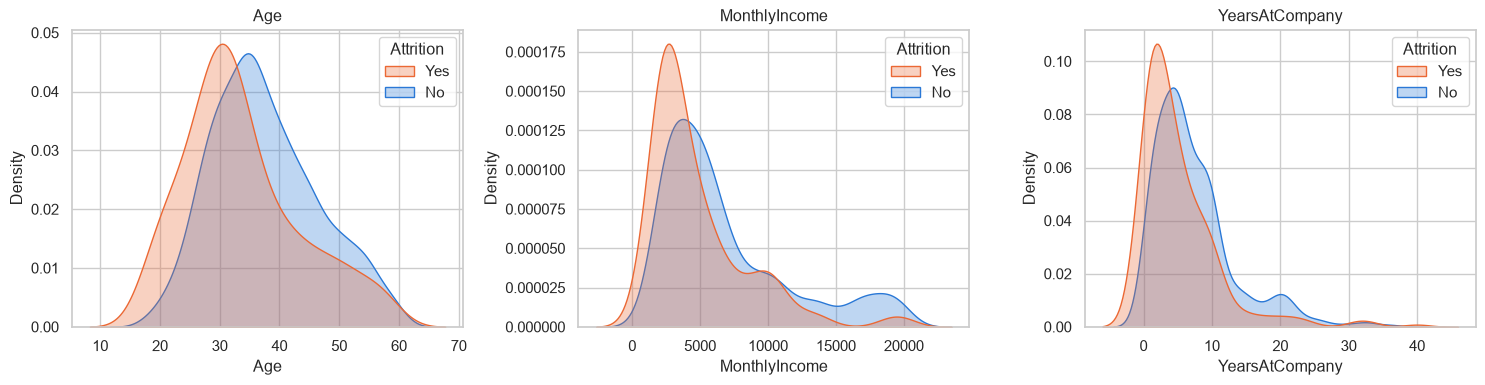

,Age,MonthlyIncome,YearsAtCompany,TotalWorkingYears
Attrition,,,,
No,36.0,5204.0,6.0,10.0
Yes,32.0,3202.0,3.0,7.0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "MonthlyIncome", "YearsAtCompany"]):
    sns.kdeplot(data=df, x=col, hue="Attrition", common_norm=False, fill=True, alpha=0.3,
                palette=PALETTE, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

df.groupby("Attrition")[["Age", "MonthlyIncome", "YearsAtCompany", "TotalWorkingYears"]].median()

Leavers are younger, earn less and have shorter tenure. All three are related to career stage, so they overlap with each other.

## 6. Correlations and statistical tests

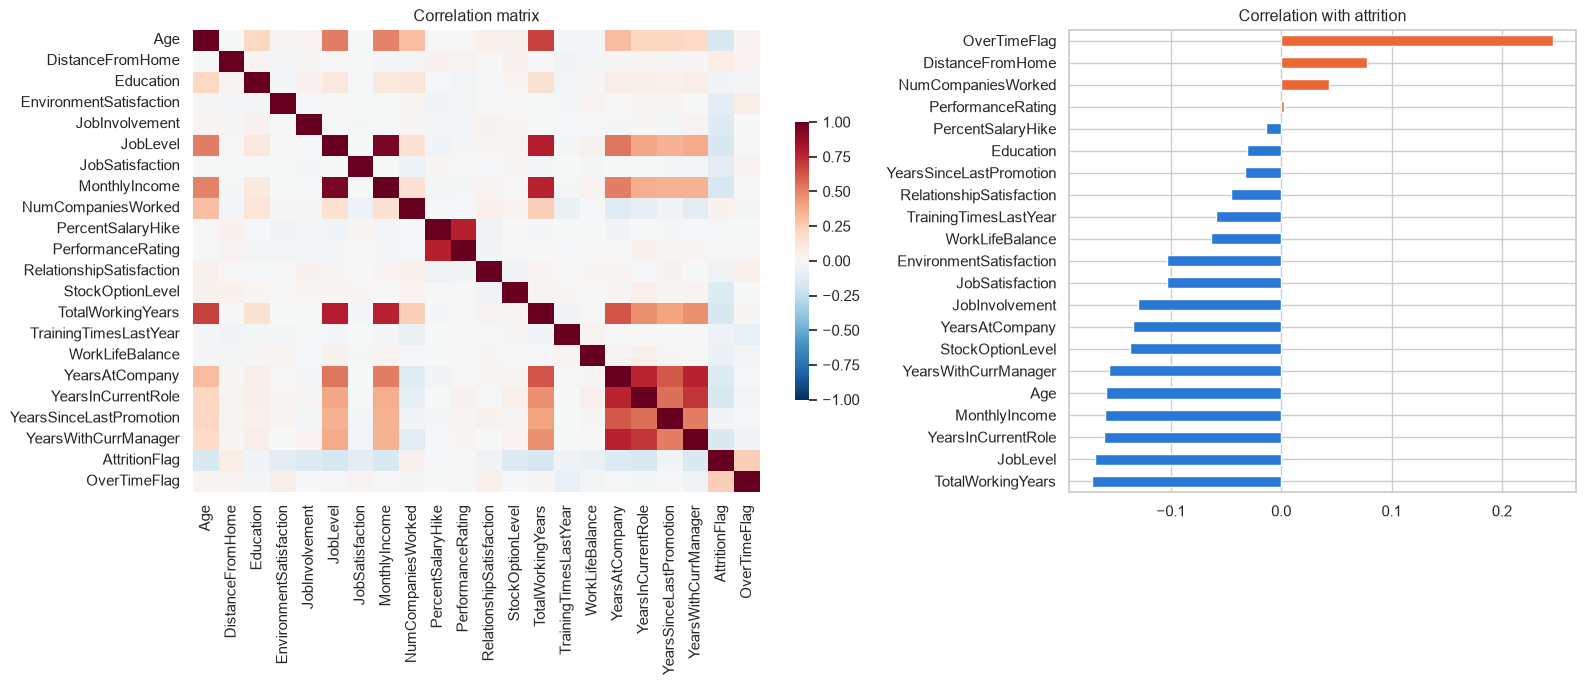

In [10]:
num = df.select_dtypes("number").drop(columns=["EmployeeNumber", "DailyRate", "HourlyRate", "MonthlyRate"])
num = num.assign(OverTimeFlag=(df["OverTime"] == "Yes").astype(int))
corr = num.corr()
target_corr = corr["AttritionFlag"].drop("AttritionFlag").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0], cbar_kws={"shrink": 0.6})
axes[0].set_title("Correlation matrix")
target_corr.plot.barh(ax=axes[1], color=[ORANGE if v > 0 else BLUE for v in target_corr])
axes[1].set_title("Correlation with attrition")
plt.tight_layout(); plt.show()

- The strongest linear relationship is with **overtime** (+0.25). Next come total working years, job level, years in role, income and age, all negative and all around -0.15 to -0.17.
- Tenure, age, income and job level are **strongly correlated with each other** (r > 0.7 in places). That multicollinearity makes logistic regression coefficients unstable, so feature importance should be read with care. A tree model such as XGBoost handles it more gracefully.

In [11]:
# Chi-square test: is attrition independent of overtime / marital status / travel?
rows = []
for col in ["OverTime", "MaritalStatus", "BusinessTravel", "JobRole", "Department", "Gender"]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[col], df["Attrition"]))
    rows.append({"feature": col, "chi2": chi2, "dof": dof, "p_value": p})
chi = pd.DataFrame(rows).sort_values("p_value")

# Mann-Whitney U: do leavers earn less? (income is skewed, so non-parametric)
u, p_income = stats.mannwhitneyu(df.loc[df.AttritionFlag == 1, "MonthlyIncome"],
                                 df.loc[df.AttritionFlag == 0, "MonthlyIncome"], alternative="less")
print(f"Mann-Whitney U (leavers earn less): p = {p_income:.2e}")
chi.style.format({"chi2": "{:.1f}", "p_value": "{:.2e}"}).hide(axis="index")

Mann-Whitney U (leavers earn less): p = 1.48e-14


feature,chi2,dof,p_value
OverTime,87.6,1,8.16e-21
JobRole,86.2,8,2.75e-15
MaritalStatus,46.2,2,9.46e-11
BusinessTravel,24.2,2,5.61e-06
Department,10.8,2,4.53e-03
Gender,1.1,1,2.91e-01


- Overtime, job role, marital status and travel are all highly significant (p << 0.001). **Gender is not significant**, which is a useful fairness point: gender is not a driver in this data.
- Leavers earn significantly less (Mann-Whitney, p << 0.001).

## 7. Same questions in SQL

In [12]:
db_path = build_database(raw)
queries = parse_queries()
with sqlite3.connect(db_path) as conn:
    role_rank = pd.read_sql_query(queries["role_rank"].sql, conn)
    pay_vs_peers = pd.read_sql_query(queries["pay_vs_peers"].sql, conn)
print(queries["role_rank"].sql)
role_rank.head(5)

WITH role_stats AS (
    SELECT
        Department,
        JobRole,
        COUNT(*)                                                AS employees,
        SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)      AS leavers,
        AVG(CASE WHEN Attrition = 'Yes' THEN 1.0 ELSE 0.0 END)  AS attrition_rate,
        AVG(MonthlyIncome)                                      AS avg_income
    FROM employees
    GROUP BY Department, JobRole
    HAVING COUNT(*) >= 10          -- ignore tiny groups with unstable rates
)
SELECT
    RANK()       OVER (ORDER BY attrition_rate DESC)                          AS company_rank,
    DENSE_RANK() OVER (PARTITION BY Department ORDER BY attrition_rate DESC)  AS dept_rank,
    Department,
    JobRole,
    employees,
    leavers,
    ROUND(attrition_rate, 4)                                                  AS attrition_rate,
    ROUND(avg_income, 0)                                                      AS avg_income
FROM role_stats
ORDER BY company_rank;


,company_rank,dept_rank,Department,JobRole,employees,leavers,attrition_rate,avg_income
0,1,1,Sales,Sales Representative,83,33,0.3976,2626.0
1,2,1,Research & Development,Laboratory Technician,259,62,0.2394,3237.0
2,3,1,Human Resources,Human Resources,52,12,0.2308,4236.0
3,4,2,Sales,Sales Executive,326,57,0.1748,6924.0
4,5,2,Research & Development,Research Scientist,292,47,0.1610,3240.0


In [13]:
pay_vs_peers

,pay_position,employees,leavers,attrition_rate
0,1 Below peers (>10%),506,101,0.1996
1,2 Within +/-10% of peers,553,77,0.1392
2,3 Above peers (>10%),411,59,0.1436


The SQL window-function query confirms the pay story at the peer level. Employees paid more than 10% below the average for their department and job level leave at about 20%, against about 14% for those paid in line with peers. **Relative pay matters, not just absolute pay.**

## 8. Summary of findings

| # | Finding | Implication |
|---|---------|-------------|
| 1 | Overtime workers leave at about 3x the rate of others | Audit workload and overtime policy first. It is the largest single lever. |
| 2 | About half of all leavers go within 3 years, with the highest risk in the first two years (0-1 yrs) | Invest in onboarding, buddy schemes and early-career check-ins. |
| 3 | Junior, low-paid roles (Sales Rep, Lab Tech, Job level 1) dominate attrition | Review pay bands and career paths for these roles. |
| 4 | Pay below peers raises attrition, even within the same level | Run a pay-equity review against peer benchmarks. |
| 5 | Single employees, frequent travellers and those with no stock options are at higher risk | Use these as features in the risk model. Consider retention equity. |
| 6 | Gender is not a significant driver | A good fairness baseline for the model. |

**For modelling:** use class weights for the 16% minority class, judge models on recall and ROC-AUC, and expect overtime, stock options, job level/role and tenure to rank highly in feature importance.